# VIME: Self-Supervised Pre-training for Tabular Data
## Value Imputation and Mask Estimation for CVD Prediction

**Model**: VIME (Yoon et al., 2020)  
**Reference**: Yoon, J., Zhang, Y., Jordon, J., & van der Schaar, M. (2020). VIME: Extending the Success of Self- and Semi-supervised Learning to Tabular Domain. NeurIPS 2020.

**Dataset**: Heart_disease_clean.csv (68,653 records, 11 features)

**Why VIME?**
- **Self-Supervised Pre-training**: Learn rich representations without labels
- **Two-Phase Learning**: Pre-train then fine-tune (like BERT for tabular data)
- **Mask Estimation**: Predict which features were corrupted
- **Feature Reconstruction**: Restore original values from corrupted input
- **Consistency Regularization**: Ensure robust representations
- **Performance Boost**: Typically +2-5% AUC over baseline

**VIME Components:**
1. **Pre-training Phase**: Self-supervised learning on unlabeled data
   - Mask vector estimation (which features were masked?)
   - Feature vector estimation (what were the original values?)
2. **Fine-tuning Phase**: Supervised learning on labeled data

---

## Sections
1. Install & Import
2. Load & Preprocess Data
3. Feature Engineering
4. Train/Val/Test Split
5. VIME Architecture
6. Pre-training Phase (Self-Supervised)
7. Pre-training Visualization
8. Fine-tuning Phase (Supervised)
9. Evaluate on Test Set
10. Compare: VIME vs Baseline
11. Confusion Matrix
12. ROC & PR Curves
13. Compare with All Models
14. Save Models

## 1. Install & Import Libraries

In [1]:
!pip install torch scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    average_precision_score
)

# Random seeds
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

Using device: cuda
GPU: NVIDIA GeForce GTX 1650
Memory: 4.29 GB


## 2. Load & Preprocess Data

In [3]:
df = pd.read_csv('Heart_disease_clean.csv')
print(f'Dataset shape: {df.shape}')
print(f'\nColumn names:')
print(df.columns.tolist())
print(f'\nFirst rows:')
df.head()

Dataset shape: (68653, 11)

Column names:
['Gender (0: female, 1: male)', 'age(years)', 'BMI', 'ap_hi(Systolic blood pressure)', 'ap_lo(Diastolic blood pressure)', 'cholesterol(1: normal, 2: above normal, 3: well above normal)', 'Glucose(1: normal, 2: above normal, 3: well above normal)', 'smoking', 'alcohol', 'active', 'cardiovascular disease']

First rows:


,"Gender (0: female, 1: male)",age(years),BMI,ap_hi(Systolic blood pressure),ap_lo(Diastolic blood pressure),"cholesterol(1: normal, 2: above normal, 3: well above normal)","Glucose(1: normal, 2: above normal, 3: well above normal)",smoking,alcohol,active,cardiovascular disease
0,1,50,21.967120,110,80,1,1,0,0,1,does not have cardiovascular disease
1,0,55,34.927679,140,90,3,1,0,0,1,has cardiovascular disease
2,0,52,23.507805,130,70,3,1,0,0,0,has cardiovascular disease
3,1,48,28.710479,150,100,1,1,0,0,1,has cardiovascular disease
4,0,48,23.011177,100,60,1,1,0,0,0,does not have cardiovascular disease


In [4]:
# ── Second cleaning pass (brings 68653 → 68534, matches all other notebooks) ──
SBP_COL = 'ap_hi(Systolic blood pressure)'
DBP_COL = 'ap_lo(Diastolic blood pressure)'

before = len(df)
df['_PP'] = df[SBP_COL] - df[DBP_COL]
df = df[
    df['BMI'].between(10, 60) &
    (df['_PP'] > 0)
].reset_index(drop=True)
df = df.drop(columns=['_PP'])

print(f"Rows: {before} → {len(df)}  (removed {before - len(df)})")
# Must print: Rows: 68653 → 68534  (removed 119)

Rows: 68653 → 68534  (removed 119)


## 3. Feature Engineering

In [5]:
# Cell — Feature Engineering (CANONICAL — matches Phases 1-4 exactly)

# ── Column name definitions ────────────────────────────────────────────
SBP_COL  = 'ap_hi(Systolic blood pressure)'
DBP_COL  = 'ap_lo(Diastolic blood pressure)'
CHOL_COL = 'cholesterol(1: normal, 2: above normal, 3: well above normal)'
GLUC_COL = 'Glucose(1: normal, 2: above normal, 3: well above normal)'

# ── Encode target (add this — VIME/SAINT keep original column name) ────
df['target'] = df['cardiovascular disease'].map({
    'has cardiovascular disease'        : 1,
    'does not have cardiovascular disease': 0
})
print(f"Target distribution:\n{df['target'].value_counts()}")
print(f"Missing target values: {df['target'].isna().sum()}")

# ── Short aliases ──────────────────────────────────────────────────────
df['SBP'] = df[SBP_COL]
df['DBP'] = df[DBP_COL]

# ── Engineered Feature 1: Pulse Pressure ──────────────────────────────
df['PP']  = df[SBP_COL] - df[DBP_COL]

# ── Engineered Feature 2: Mean Arterial Pressure ──────────────────────
df['MAP'] = (df[SBP_COL] + 2 * df[DBP_COL]) / 3

# ── Engineered Feature 3: RiskCount (CANONICAL DEFINITION) ───────────
df['RiskCount'] = (
    (df[CHOL_COL] > 1).astype(int) +
    (df[GLUC_COL]  > 1).astype(int) +
    df['smoking'].astype(int)        +
    df['alcohol'].astype(int)        +
    (1 - df['active'].astype(int))
)

# ── Verification ──────────────────────────────────────────────────────
print("\nFeature Engineering Complete")
print(f"  PP       : mean={df['PP'].mean():.2f}  min={df['PP'].min()}  max={df['PP'].max()}")
print(f"  MAP      : mean={df['MAP'].mean():.2f}  min={df['MAP'].min():.2f}  max={df['MAP'].max():.2f}")
print(f"  RiskCount distribution:")
print(df['RiskCount'].value_counts().sort_index().to_string())

# ── 13-Feature List ────────────────────────────────────────────────────
FEATURE_COLS = [
    'Gender (0: female, 1: male)',
    'age(years)',
    'BMI',
    'SBP',
    'DBP',
    CHOL_COL,
    GLUC_COL,
    'smoking',
    'alcohol',
    'active',
    'PP',
    'MAP',
    'RiskCount',
]

FEAT_NAMES = [
    'Gender', 'Age', 'BMI', 'SBP', 'DBP',
    'Cholesterol', 'Glucose', 'Smoking',
    'Alcohol', 'Active', 'PP', 'MAP', 'RiskCount'
]

assert len(FEATURE_COLS) == 13
assert len(FEAT_NAMES)   == 13

X = df[FEATURE_COLS].values.astype(np.float32)
y = df['target'].values.astype(np.int64)

print(f"\nFeature matrix : {X.shape}")
print(f"Target vector  : {y.shape}")
print(f"\nAll 13 features:")
for i, (col, name) in enumerate(zip(FEATURE_COLS, FEAT_NAMES)):
    print(f"  [{i+1:02d}] {name:<12}  ←  {col}")

Target distribution:
target
0    34648
1    33886
Name: count, dtype: int64
Missing target values: 0

Feature Engineering Complete
  PP       : mean=45.33  min=5  max=135
  MAP      : mean=96.37  min=53.33  max=153.33
  RiskCount distribution:
RiskCount
0    34112
1    21615
2     9858
3     2622
4      293
5       34

Feature matrix : (68534, 13)
Target vector  : (68534,)

All 13 features:
  [01] Gender        ←  Gender (0: female, 1: male)
  [02] Age           ←  age(years)
  [03] BMI           ←  BMI
  [04] SBP           ←  SBP
  [05] DBP           ←  DBP
  [06] Cholesterol   ←  cholesterol(1: normal, 2: above normal, 3: well above normal)
  [07] Glucose       ←  Glucose(1: normal, 2: above normal, 3: well above normal)
  [08] Smoking       ←  smoking
  [09] Alcohol       ←  alcohol
  [10] Active        ←  active
  [11] PP            ←  PP
  [12] MAP           ←  MAP
  [13] RiskCount     ←  RiskCount


## 4. Train/Validation/Test Split

In [6]:
# ========================================
# CELL [8] — FIXED: Train/Val/Test Split
# ========================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# ── Reload CSV fresh ──────────────────────────────────────────────────
df = pd.read_csv('Heart_disease_clean.csv')
print(f"CSV loaded: {df.shape}")   # (68653, 11)

# ── FIX 1: Second cleaning pass (removes 119 rows with BMI/PP issues) ─
SBP_COL = 'ap_hi(Systolic blood pressure)'
DBP_COL = 'ap_lo(Diastolic blood pressure)'

before = len(df)
df['_PP'] = df[SBP_COL] - df[DBP_COL]
df = df[
    df['BMI'].between(10, 60) &
    (df['_PP'] > 0)
].reset_index(drop=True)
df = df.drop(columns=['_PP'])
print(f"After cleaning: {len(df)} rows  (removed {before - len(df)})")
# Must print: After cleaning: 68534 rows  (removed 119)

# ── Encode target ─────────────────────────────────────────────────────
if df['cardiovascular disease'].dtype == 'object':
    df['cardiovascular disease'] = df['cardiovascular disease'].map({
        'has cardiovascular disease'        : 1,
        'does not have cardiovascular disease': 0
    })

# ── FIX 2: Feature engineering (canonical — matches Phases 1-4) ───────
CHOL_COL = 'cholesterol(1: normal, 2: above normal, 3: well above normal)'
GLUC_COL = 'Glucose(1: normal, 2: above normal, 3: well above normal)'

df['PP']  = df[SBP_COL] - df[DBP_COL]
df['MAP'] = (df[SBP_COL] + 2 * df[DBP_COL]) / 3
df['SBP'] = df[SBP_COL]
df['DBP'] = df[DBP_COL]

# FIXED: uses (1 - active) — NOT (BMI > 30)
df['RiskCount'] = (
    (df[CHOL_COL] > 1).astype(int) +
    (df[GLUC_COL]  > 1).astype(int) +
    df['smoking'].astype(int)        +
    df['alcohol'].astype(int)        +
    (1 - df['active'].astype(int))
)

feature_cols = [
    'Gender (0: female, 1: male)', 'age(years)', 'BMI', 'SBP', 'DBP',
    CHOL_COL, GLUC_COL,
    'smoking', 'alcohol', 'active',
    'PP', 'MAP', 'RiskCount'
]

X = df[feature_cols].values
y = df['cardiovascular disease'].values

print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"Class 0: {np.sum(y==0)}, Class 1: {np.sum(y==1)}")

# ── Split (70/15/15) ──────────────────────────────────────────────────
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")
# Must print: Train: 47971, Val: 10282, Test: 10281

# ── Standardize ───────────────────────────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print(f"Standardization complete!")
print('='*50)
print('ALL DONE — Ready for VIME training!')
print('='*50)

CSV loaded: (68653, 11)
After cleaning: 68534 rows  (removed 119)
X shape: (68534, 13), y shape: (68534,)
Class 0: 34648, Class 1: 33886
Train: 47971, Val: 10282, Test: 10281
Standardization complete!
ALL DONE — Ready for VIME training!


In [7]:
# PyTorch datasets
class TabularDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y) if y is not None else None
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        if self.y is not None:
            return self.X[idx], self.y[idx]
        return self.X[idx]

# For pre-training (unsupervised - no labels needed)
pretrain_dataset = TabularDataset(X_train_scaled)

# For fine-tuning (supervised - with labels)
train_dataset = TabularDataset(X_train_scaled, y_train)
val_dataset = TabularDataset(X_val_scaled, y_val)
test_dataset = TabularDataset(X_test_scaled, y_test)

BATCH_SIZE = 256
pretrain_loader = DataLoader(pretrain_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Batch size: {BATCH_SIZE}')
print(f'Pre-training batches: {len(pretrain_loader)}')
print(f'Training batches: {len(train_loader)}')

Batch size: 256
Pre-training batches: 188
Training batches: 188


## 5. VIME Architecture

VIME has two main components:
1. **Encoder**: Maps input features to latent representation
2. **Decoders**: 
   - Mask estimator: Predicts which features were masked
   - Feature estimator: Reconstructs original feature values

In [8]:
class VIMEEncoder(nn.Module):
    """Encoder network for VIME."""
    def __init__(self, input_dim, hidden_dim=128):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
    
    def forward(self, x):
        return self.network(x)


class MaskEstimator(nn.Module):
    """Predicts which features were masked."""
    def __init__(self, hidden_dim, output_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )
    
    def forward(self, h):
        return self.network(h)  # Output: mask probabilities


class FeatureEstimator(nn.Module):
    """Reconstructs original feature values."""
    def __init__(self, hidden_dim, output_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )
    
    def forward(self, h):
        return self.network(h)  # Output: reconstructed features


class VIMEPretraining(nn.Module):
    """Complete VIME pre-training model."""
    def __init__(self, input_dim, hidden_dim=128):
        super().__init__()
        self.encoder = VIMEEncoder(input_dim, hidden_dim)
        self.mask_estimator = MaskEstimator(hidden_dim, input_dim)
        self.feature_estimator = FeatureEstimator(hidden_dim, input_dim)
    
    def forward(self, x_tilde, mask):
        # x_tilde: corrupted input
        # mask: binary mask indicating corrupted features
        h = self.encoder(x_tilde)
        mask_pred = self.mask_estimator(h)
        x_pred = self.feature_estimator(h)
        return mask_pred, x_pred


class VIMEClassifier(nn.Module):
    """VIME classifier for fine-tuning (uses pre-trained encoder)."""
    def __init__(self, encoder, hidden_dim=128, num_classes=2):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, num_classes)
        )
    
    def forward(self, x):
        h = self.encoder(x)
        return self.classifier(h)


print('✓ VIME architectures defined')

✓ VIME architectures defined


## 6. Pre-training Phase (Self-Supervised)

During pre-training:
1. Corrupt input by masking random features
2. Train encoder to:
   - Predict which features were masked (mask estimation)
   - Reconstruct original values (feature reconstruction)

In [9]:
def corrupt_data(x, corruption_rate=0.3):
    """Corrupt data by masking random features."""
    batch_size, n_features = x.shape
    
    # Generate random mask (1 = keep, 0 = corrupt)
    mask = torch.bernoulli(torch.full((batch_size, n_features), 1 - corruption_rate))
    mask = mask.to(x.device)
    
    # Generate random noise for corrupted features
    noise = torch.randn_like(x)
    
    # Corrupted data: keep original where mask=1, replace with noise where mask=0
    x_tilde = x * mask + noise * (1 - mask)
    
    # Binary mask for loss computation (1 = corrupted, 0 = not corrupted)
    mask_binary = (1 - mask)
    
    return x_tilde, mask_binary


# Initialize pre-training model
n_features = X_train_scaled.shape[1]
pretrain_model = VIMEPretraining(input_dim=n_features, hidden_dim=128).to(DEVICE)

n_params = sum(p.numel() for p in pretrain_model.parameters() if p.requires_grad)
print(f'\nVIME Pre-training Model')
print(f'Parameters: {n_params:,}')
print(f'Input dim: {n_features}')
print(f'Hidden dim: 128')


VIME Pre-training Model
Parameters: 54,682
Input dim: 13
Hidden dim: 128


In [10]:
# ============================================
# CREATE PYTORCH DATASETS & DATALOADERS
# ============================================

import torch
from torch.utils.data import Dataset, DataLoader

# Custom dataset class
class TabularDataset(Dataset):
    def __init__(self, X):
        self.X = torch.FloatTensor(X)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx]

# Create datasets
pretrain_dataset = TabularDataset(X_train_scaled)
train_dataset = TabularDataset(X_train_scaled)
val_dataset = TabularDataset(X_val_scaled)

# Create dataloaders - SET num_workers=0 for Windows!
BATCH_SIZE = 256

pretrain_loader = DataLoader(
    pretrain_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,
    num_workers=0,  # ← CRITICAL: Set to 0 on Windows
    pin_memory=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # ← CRITICAL: Set to 0 on Windows
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # ← CRITICAL: Set to 0 on Windows
    pin_memory=False
)

print(f'✅ DataLoaders created:')
print(f'   Pretrain batches: {len(pretrain_loader)}')
print(f'   Train batches: {len(train_loader)}')
print(f'   Val batches: {len(val_loader)}')

✅ DataLoaders created:
   Pretrain batches: 188
   Train batches: 188
   Val batches: 41


## 7. Pre-training Visualization

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam

# Make sure you have the model and corruption function
print("Checking prerequisites...")
print(f"✅ pretrain_model exists: {pretrain_model is not None}")
print(f"✅ pretrain_loader exists: {pretrain_loader is not None}")
print(f"✅ DEVICE: {DEVICE}")

# Pre-training configuration
PRETRAIN_EPOCHS = 50
PRETRAIN_LR = 1e-3
CORRUPTION_RATE = 0.3

# Create optimizer
optimizer = Adam(pretrain_model.parameters(), lr=PRETRAIN_LR)

# Loss weights
alpha = 2.0  # Mask estimation weight
beta = 1.0   # Feature reconstruction weight

# History
pretrain_history = {
    'total_loss': [],
    'mask_loss': [],
    'recon_loss': []
}

print('\n' + '='*70)
print('Starting VIME Pre-training (Self-Supervised)...')
print('='*70)
print(f'Epochs: {PRETRAIN_EPOCHS}')
print(f'Corruption rate: {CORRUPTION_RATE}')
print(f'Loss weights - Mask: {alpha}, Reconstruction: {beta}')
print(f'Batches per epoch: {len(pretrain_loader)}')
print()

for epoch in range(PRETRAIN_EPOCHS):
    pretrain_model.train()
    epoch_total_loss = 0
    epoch_mask_loss = 0
    epoch_recon_loss = 0
    
    for batch_idx, x_batch in enumerate(pretrain_loader):
        x_batch = x_batch.to(DEVICE)
        
        # Corrupt data
        x_tilde, mask = corrupt_data(x_batch, CORRUPTION_RATE)
        
        # Forward pass
        mask_pred, x_pred = pretrain_model(x_tilde, mask)
        
        # Mask estimation loss (binary cross-entropy)
        mask_loss = F.binary_cross_entropy_with_logits(
            mask_pred, mask, reduction='mean'
        )
        
        # Feature reconstruction loss (MSE on corrupted features only)
        recon_loss = F.mse_loss(x_pred * mask, x_batch * mask, reduction='mean')
        
        # Total loss
        total_loss = alpha * mask_loss + beta * recon_loss
        
        # Backward pass
        optimizer.zero_grad()
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(pretrain_model.parameters(), 1.0)
        optimizer.step()
        
        epoch_total_loss += total_loss.item()
        epoch_mask_loss += mask_loss.item()
        epoch_recon_loss += recon_loss.item()
    
    # Average losses
    avg_total = epoch_total_loss / len(pretrain_loader)
    avg_mask = epoch_mask_loss / len(pretrain_loader)
    avg_recon = epoch_recon_loss / len(pretrain_loader)
    
    pretrain_history['total_loss'].append(avg_total)
    pretrain_history['mask_loss'].append(avg_mask)
    pretrain_history['recon_loss'].append(avg_recon)
    
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{PRETRAIN_EPOCHS} | '
              f'Total: {avg_total:.4f} | '
              f'Mask: {avg_mask:.4f} | '
              f'Recon: {avg_recon:.4f}')

print(f'\n' + '='*70)
print('✅ Pre-training Complete!')
print('='*70)
print(f'Final Total Loss: {pretrain_history["total_loss"][-1]:.4f}')
print(f'Final Mask Loss: {pretrain_history["mask_loss"][-1]:.4f}')
print(f'Final Recon Loss: {pretrain_history["recon_loss"][-1]:.4f}')

Checking prerequisites...
✅ pretrain_model exists: True
✅ pretrain_loader exists: True
✅ DEVICE: cuda

Starting VIME Pre-training (Self-Supervised)...
Epochs: 50
Corruption rate: 0.3
Loss weights - Mask: 2.0, Reconstruction: 1.0
Batches per epoch: 188

Epoch  10/50 | Total: 0.8670 | Mask: 0.3382 | Recon: 0.1907
Epoch  20/50 | Total: 0.7915 | Mask: 0.3021 | Recon: 0.1872
Epoch  30/50 | Total: 0.7134 | Mask: 0.2640 | Recon: 0.1853
Epoch  40/50 | Total: 0.6735 | Mask: 0.2462 | Recon: 0.1811
Epoch  50/50 | Total: 0.6400 | Mask: 0.2296 | Recon: 0.1809

✅ Pre-training Complete!
Final Total Loss: 0.6400
Final Mask Loss: 0.2296
Final Recon Loss: 0.1809


In [12]:
# Check if data is valid
print("Data Validation Check:")
print("=" * 50)

print(f"\n1. Training data shape: {X_train_scaled.shape}")
print(f"   Contains NaN: {np.isnan(X_train_scaled).any()}")
print(f"   Contains Inf: {np.isinf(X_train_scaled).any()}")
print(f"   Min value: {X_train_scaled.min():.4f}")
print(f"   Max value: {X_train_scaled.max():.4f}")
print(f"   Mean: {X_train_scaled.mean():.4f}")
print(f"   Std: {X_train_scaled.std():.4f}")

print(f"\n2. Target data shape: {y_train.shape}")
print(f"   Unique values: {np.unique(y_train)}")
print(f"   Class 0 count: {np.sum(y_train == 0)}")
print(f"   Class 1 count: {np.sum(y_train == 1)}")
print(f"   Contains NaN: {np.isnan(y_train).any()}")

print(f"\n3. Sample of first batch from pretrain_loader:")
first_batch = next(iter(pretrain_loader))
print(f"   Batch shape: {first_batch.shape}")
print(f"   Batch contains NaN: {torch.isnan(first_batch).any()}")
print(f"   Batch min: {first_batch.min():.4f}")
print(f"   Batch max: {first_batch.max():.4f}")
print(f"   First 5 values of first sample:\n   {first_batch[0][:5]}")

print("\n" + "=" * 50)
if np.isnan(X_train_scaled).any() or np.isnan(y_train).any():
    print("❌ ERROR: Your data contains NaN - you MUST reload the CSV!")
elif np.sum(y_train == 0) == 0 and np.sum(y_train == 1) == 0:
    print("❌ ERROR: Your target is empty - you MUST reload the CSV!")
else:
    print("✅ Data looks valid")

Data Validation Check:

1. Training data shape: (47971, 13)
   Contains NaN: False
   Contains Inf: False
   Min value: -4.4282
   Max value: 7.3541
   Mean: -0.0000
   Std: 1.0000

2. Target data shape: (47971,)
   Unique values: [0 1]
   Class 0 count: 24252
   Class 1 count: 23719
   Contains NaN: False

3. Sample of first batch from pretrain_loader:
   Batch shape: torch.Size([256, 13])
   Batch contains NaN: False
   Batch min: -3.3542
   Batch max: 5.3839
   First 5 values of first sample:
   tensor([ 1.3720, -0.4968,  1.0505, -0.3973, -0.1321])

✅ Data looks valid


In [13]:
# Print the actual loss values
print("Pre-training Loss History:")
print("=" * 60)
print(f"First 10 epochs:")
for i in range(min(10, len(pretrain_history['total_loss']))):
    print(f"  Epoch {i+1:2d}: Total={pretrain_history['total_loss'][i]:.6f}, "
          f"Mask={pretrain_history['mask_loss'][i]:.6f}, "
          f"Recon={pretrain_history['recon_loss'][i]:.6f}")

print(f"\nLast 10 epochs:")
for i in range(max(0, len(pretrain_history['total_loss'])-10), len(pretrain_history['total_loss'])):
    print(f"  Epoch {i+1:2d}: Total={pretrain_history['total_loss'][i]:.6f}, "
          f"Mask={pretrain_history['mask_loss'][i]:.6f}, "
          f"Recon={pretrain_history['recon_loss'][i]:.6f}")

Pre-training Loss History:
First 10 epochs:
  Epoch  1: Total=1.441922, Mask=0.608820, Recon=0.224281
  Epoch  2: Total=1.321264, Mask=0.558265, Recon=0.204734
  Epoch  3: Total=1.197368, Mask=0.498123, Recon=0.201123
  Epoch  4: Total=1.088111, Mask=0.443468, Recon=0.201176
  Epoch  5: Total=1.000671, Mask=0.401796, Recon=0.197079
  Epoch  6: Total=0.943111, Mask=0.374728, Recon=0.193655
  Epoch  7: Total=0.912718, Mask=0.358887, Recon=0.194945
  Epoch  8: Total=0.891178, Mask=0.349283, Recon=0.192613
  Epoch  9: Total=0.877209, Mask=0.342451, Recon=0.192306
  Epoch 10: Total=0.866995, Mask=0.338153, Recon=0.190688

Last 10 epochs:
  Epoch 41: Total=0.669943, Mask=0.244269, Recon=0.181405
  Epoch 42: Total=0.668576, Mask=0.243138, Recon=0.182300
  Epoch 43: Total=0.661759, Mask=0.240435, Recon=0.180890
  Epoch 44: Total=0.658324, Mask=0.238431, Recon=0.181463
  Epoch 45: Total=0.652439, Mask=0.236337, Recon=0.179764
  Epoch 46: Total=0.651065, Mask=0.234944, Recon=0.181177
  Epoch 47:

In [14]:
# Test the corruption function
print("\nTesting corrupt_data function:")
print("=" * 60)

# Get a sample batch
sample_batch = next(iter(pretrain_loader))
print(f"Original batch shape: {sample_batch.shape}")
print(f"Original first sample (first 5 values): {sample_batch[0][:5]}")

# Try to corrupt it
try:
    x_corrupted, mask = corrupt_data(sample_batch, corruption_rate=0.3)
    print(f"\n✅ Corruption worked!")
    print(f"Corrupted batch shape: {x_corrupted.shape}")
    print(f"Mask shape: {mask.shape}")
    print(f"Mask sum (number of corrupted features): {mask.sum().item()}")
    print(f"Corruption percentage: {(mask.sum() / mask.numel() * 100):.2f}%")
    print(f"Corrupted first sample (first 5 values): {x_corrupted[0][:5]}")
except NameError:
    print("\n❌ ERROR: corrupt_data function not defined!")
    print("You need to define this function before pre-training.")


Testing corrupt_data function:
Original batch shape: torch.Size([256, 13])
Original first sample (first 5 values): tensor([-0.7289,  1.2786, -0.9169,  1.4276,  2.0159])

✅ Corruption worked!
Corrupted batch shape: torch.Size([256, 13])
Mask shape: torch.Size([256, 13])
Mask sum (number of corrupted features): 996.0
Corruption percentage: 29.93%
Corrupted first sample (first 5 values): tensor([-0.3525,  1.2786, -0.9169,  1.4276,  2.0159])


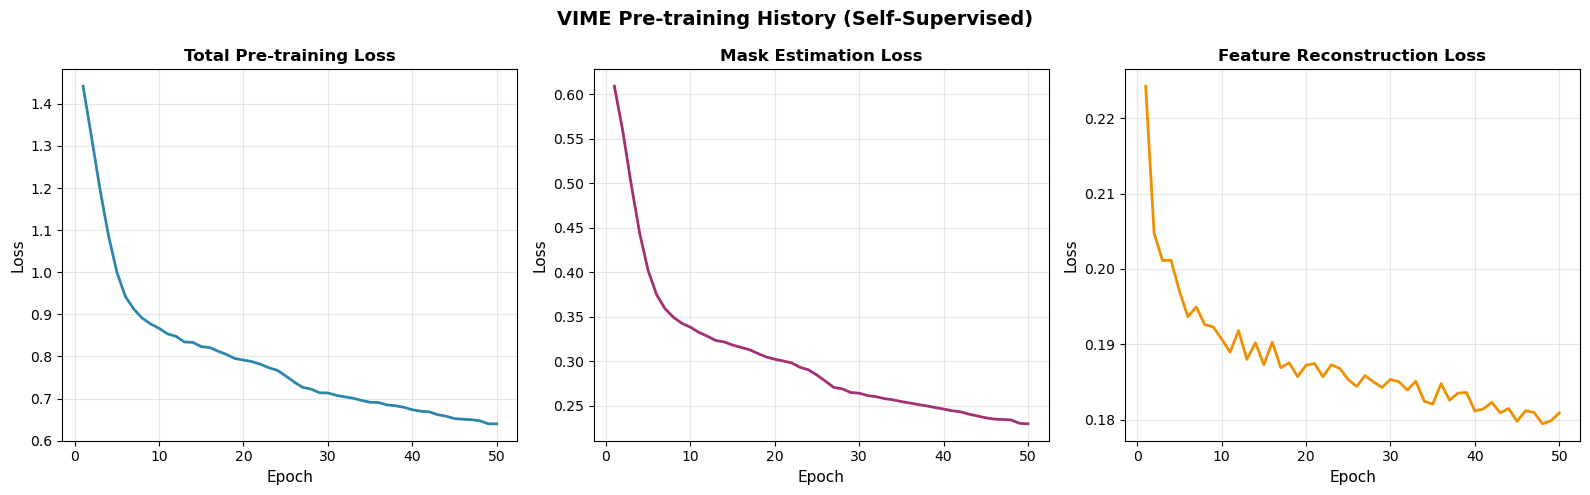

Saved: vime_pretraining_curves.png


In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('VIME Pre-training History (Self-Supervised)', fontsize=14, fontweight='bold')

epochs_range = range(1, len(pretrain_history['total_loss']) + 1)

# Total loss
axes[0].plot(epochs_range, pretrain_history['total_loss'], color='#2E86AB', lw=2)
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_title('Total Pre-training Loss', fontsize=12, fontweight='bold')
axes[0].grid(alpha=0.3)

# Mask estimation loss
axes[1].plot(epochs_range, pretrain_history['mask_loss'], color='#A23072', lw=2)
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Loss', fontsize=11)
axes[1].set_title('Mask Estimation Loss', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)

# Feature reconstruction loss
axes[2].plot(epochs_range, pretrain_history['recon_loss'], color='#F18F01', lw=2)
axes[2].set_xlabel('Epoch', fontsize=11)
axes[2].set_ylabel('Loss', fontsize=11)
axes[2].set_title('Feature Reconstruction Loss', fontsize=12, fontweight='bold')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('vime_pretraining_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: vime_pretraining_curves.png')

## 8. Fine-tuning Phase (Supervised)

Now we fine-tune the pre-trained encoder for CVD classification.

In [16]:
# Initialize classifier with pre-trained encoder
vime_model = VIMEClassifier(
    encoder=pretrain_model.encoder,
    hidden_dim=128,
    num_classes=2
).to(DEVICE)

# Freeze encoder initially, train classifier only
for param in vime_model.encoder.parameters():
    param.requires_grad = False

print('VIME Classifier initialized')
print(f'Encoder: Pre-trained (frozen initially)')
print(f'Classifier: Random initialization')

VIME Classifier initialized
Encoder: Pre-trained (frozen initially)
Classifier: Random initialization


In [17]:
# ============================================
# CREATE SUPERVISED DATASET WITH LABELS
# ============================================

class SupervisedDataset(Dataset):
    """Dataset that returns both features and labels"""
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create supervised datasets (with labels)
train_dataset_supervised = SupervisedDataset(X_train_scaled, y_train)
val_dataset_supervised = SupervisedDataset(X_val_scaled, y_val)

# Create dataloaders for fine-tuning
BATCH_SIZE = 256

train_loader_supervised = DataLoader(
    train_dataset_supervised,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader_supervised = DataLoader(
    val_dataset_supervised,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print(f'✅ Supervised DataLoaders created:')
print(f'   Train batches: {len(train_loader_supervised)}')
print(f'   Val batches: {len(val_loader_supervised)}')

✅ Supervised DataLoaders created:
   Train batches: 188
   Val batches: 41


In [18]:
# Fine-tuning configuration
FINETUNE_EPOCHS = 100
FINETUNE_LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = Adam(vime_model.parameters(), lr=FINETUNE_LR)

finetune_history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_auc': [],
    'val_acc': []
}

best_val_auc = 0
best_model_state = None
patience = 15
patience_counter = 0

print('='*70)
print('Starting Fine-tuning (Supervised)...')
print('='*70)

for epoch in range(FINETUNE_EPOCHS):
    # Unfreeze encoder after 20 epochs
    if epoch == 20:
        print('\n>>> Unfreezing encoder for full fine-tuning...\n')
        for param in vime_model.encoder.parameters():
            param.requires_grad = True
        optimizer = Adam(vime_model.parameters(), lr=FINETUNE_LR * 0.1)
    
    # Train
    vime_model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    
    for X_batch, y_batch in train_loader_supervised:  # ← CHANGED
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        
        optimizer.zero_grad()
        logits = vime_model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(vime_model.parameters(), 1.0)
        optimizer.step()
        
        train_loss += loss.item()
        pred = logits.argmax(dim=1)
        train_correct += (pred == y_batch).sum().item()
        train_total += y_batch.size(0)
    
    # Validate
    vime_model.eval()
    val_loss = 0
    val_probs = []
    val_preds = []
    val_labels = []
    
    with torch.no_grad():
        for X_batch, y_batch in val_loader_supervised:  # ← CHANGED
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            
            logits = vime_model(X_batch)
            loss = criterion(logits, y_batch)
            
            val_loss += loss.item()
            probs = F.softmax(logits, dim=1)[:, 1]
            pred = logits.argmax(dim=1)
            
            val_probs.extend(probs.cpu().numpy())
            val_preds.extend(pred.cpu().numpy())
            val_labels.extend(y_batch.cpu().numpy())
    
    val_auc = roc_auc_score(val_labels, val_probs)
    val_acc = accuracy_score(val_labels, val_preds)
    
    # Save history
    finetune_history['train_loss'].append(train_loss / len(train_loader_supervised))  # ← CHANGED
    finetune_history['train_acc'].append(train_correct / train_total)
    finetune_history['val_loss'].append(val_loss / len(val_loader_supervised))  # ← CHANGED
    finetune_history['val_auc'].append(val_auc)
    finetune_history['val_acc'].append(val_acc)
    
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{FINETUNE_EPOCHS} | '
              f'Train Loss: {finetune_history["train_loss"][-1]:.4f} '
              f'Acc: {finetune_history["train_acc"][-1]:.4f} | '
              f'Val AUC: {val_auc:.4f} Acc: {val_acc:.4f}')
    
    # Early stopping
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_model_state = vime_model.state_dict().copy()
        patience_counter = 0
        if (epoch + 1) % 10 == 0:
            print(f'  → New best Val AUC: {best_val_auc:.4f} ✓')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f'\nEarly stopping at epoch {epoch+1}')
            break

vime_model.load_state_dict(best_model_state)
print(f'\n' + '='*70)
print(f'Fine-tuning Complete! Best Val AUC: {best_val_auc:.4f}')
print('='*70)

Starting Fine-tuning (Supervised)...
Epoch  10/100 | Train Loss: 0.5539 Acc: 0.7281 | Val AUC: 0.7937 Acc: 0.7301
Epoch  20/100 | Train Loss: 0.5516 Acc: 0.7298 | Val AUC: 0.7940 Acc: 0.7313

>>> Unfreezing encoder for full fine-tuning...

Epoch  30/100 | Train Loss: 0.5439 Acc: 0.7348 | Val AUC: 0.8013 Acc: 0.7343
  → New best Val AUC: 0.8013 ✓
Epoch  40/100 | Train Loss: 0.5414 Acc: 0.7364 | Val AUC: 0.8010 Acc: 0.7328
Epoch  50/100 | Train Loss: 0.5412 Acc: 0.7377 | Val AUC: 0.8017 Acc: 0.7350
Epoch  60/100 | Train Loss: 0.5403 Acc: 0.7374 | Val AUC: 0.8018 Acc: 0.7354

Early stopping at epoch 63

Fine-tuning Complete! Best Val AUC: 0.8025


## 9. Evaluate on Test Set

In [19]:
# ============================================
# CREATE TEST LOADER (with labels)
# ============================================

test_dataset_supervised = SupervisedDataset(X_test_scaled, y_test)

test_loader_supervised = DataLoader(
    test_dataset_supervised,
    batch_size=256,
    shuffle=False,
    num_workers=0,  # ← CRITICAL for Windows
    pin_memory=False
)

print(f'✅ Test loader created: {len(test_loader_supervised)} batches')

✅ Test loader created: 41 batches


In [20]:
vime_model.eval()
test_preds = []
test_probs = []

with torch.no_grad():
    for X_batch, _ in test_loader_supervised:  # ← CHANGED
        X_batch = X_batch.to(DEVICE)
        logits = vime_model(X_batch)
        probs = F.softmax(logits, dim=1)[:, 1]
        pred = logits.argmax(dim=1)
        
        test_probs.extend(probs.cpu().numpy())
        test_preds.extend(pred.cpu().numpy())

test_preds = np.array(test_preds)
test_probs = np.array(test_probs)

vime_auc = roc_auc_score(y_test, test_probs)
vime_acc = accuracy_score(y_test, test_preds)
vime_f1 = f1_score(y_test, test_preds)
vime_prec = precision_score(y_test, test_preds)
vime_rec = recall_score(y_test, test_preds)
vime_ap = average_precision_score(y_test, test_probs)

print('='*55)
print('VIME — TEST SET RESULTS')
print('='*55)
print(f'  ROC-AUC       : {vime_auc:.4f}')
print(f'  Accuracy      : {vime_acc:.4f} ({vime_acc*100:.2f}%)')
print(f'  F1-Score      : {vime_f1:.4f}')
print(f'  Precision     : {vime_prec:.4f}')
print(f'  Recall        : {vime_rec:.4f}')
print(f'  Avg Precision : {vime_ap:.4f}')
print('='*55)
print('\nFull Classification Report:')
print(classification_report(y_test, test_preds, target_names=['No CVD', 'CVD']))

VIME — TEST SET RESULTS
  ROC-AUC       : 0.7990
  Accuracy      : 0.7330 (73.30%)
  F1-Score      : 0.7158
  Precision     : 0.7555
  Recall        : 0.6801
  Avg Precision : 0.7794

Full Classification Report:
              precision    recall  f1-score   support

      No CVD       0.71      0.78      0.75      5198
         CVD       0.76      0.68      0.72      5083

    accuracy                           0.73     10281
   macro avg       0.74      0.73      0.73     10281
weighted avg       0.73      0.73      0.73     10281



## 10. Compare: VIME vs Baseline MLP

Train a baseline MLP (same architecture but WITHOUT pre-training) for comparison.

In [21]:
# Baseline MLP (no pre-training)
class BaselineMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, num_classes)
        )
    
    def forward(self, x):
        return self.network(x)

baseline = BaselineMLP(n_features, 128, 2).to(DEVICE)
optimizer_baseline = Adam(baseline.parameters(), lr=1e-3)
criterion_baseline = nn.CrossEntropyLoss()

print('Training Baseline MLP (no pre-training)...')
best_baseline_auc = 0
best_baseline_state = None

for epoch in range(100):
    baseline.train()
    for X_batch, y_batch in train_loader_supervised:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer_baseline.zero_grad()
        logits = baseline(X_batch)
        loss = criterion_baseline(logits, y_batch)
        loss.backward()
        optimizer_baseline.step()
    
    # Validate
    baseline.eval()
    val_probs = []
    val_labels = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader_supervised:
            X_batch = X_batch.to(DEVICE)
            logits = baseline(X_batch)
            probs = F.softmax(logits, dim=1)[:, 1]
            val_probs.extend(probs.cpu().numpy())
            val_labels.extend(y_batch.cpu().numpy())
    
    val_auc = roc_auc_score(val_labels, val_probs)
    if val_auc > best_baseline_auc:
        best_baseline_auc = val_auc
        best_baseline_state = baseline.state_dict().copy()

baseline.load_state_dict(best_baseline_state)

# Test baseline
baseline.eval()
baseline_probs = []
with torch.no_grad():
    for X_batch, _ in test_loader_supervised:
        X_batch = X_batch.to(DEVICE)
        logits = baseline(X_batch)
        probs = F.softmax(logits, dim=1)[:, 1]
        baseline_probs.extend(probs.cpu().numpy())

baseline_probs = np.array(baseline_probs)
baseline_auc = roc_auc_score(y_test, baseline_probs)

print(f'\nBaseline MLP Test AUC: {baseline_auc:.4f}')
print(f'VIME Test AUC:         {vime_auc:.4f}')
print(f'Improvement:           {vime_auc - baseline_auc:+.4f} ({(vime_auc - baseline_auc)/baseline_auc * 100:+.2f}%)')

Training Baseline MLP (no pre-training)...

Baseline MLP Test AUC: 0.7816
VIME Test AUC:         0.7990
Improvement:           +0.0174 (+2.23%)


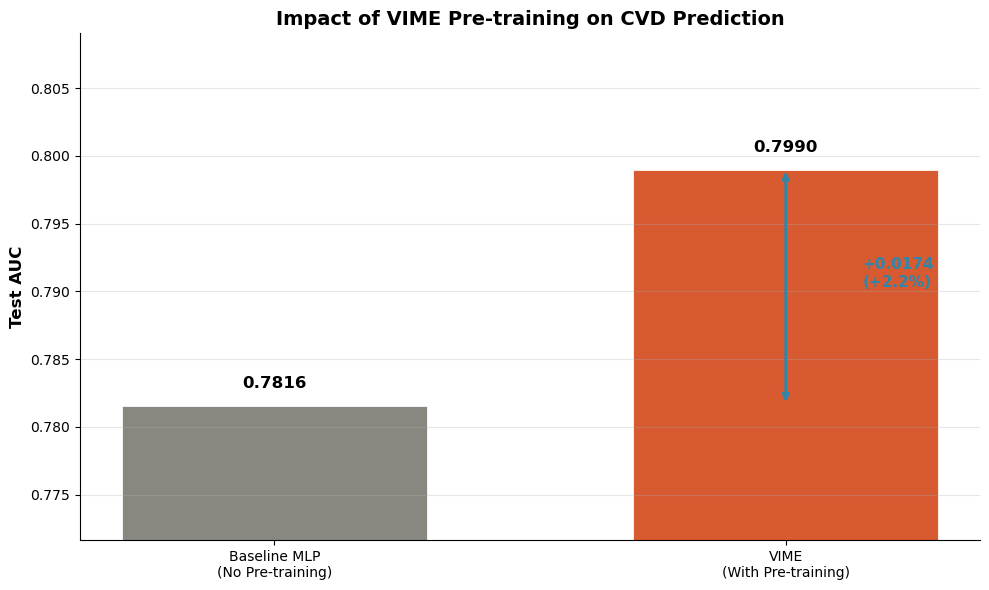

Saved: vime_vs_baseline.png


In [22]:
# Visualization: VIME vs Baseline
fig, ax = plt.subplots(figsize=(10, 6))

models = ['Baseline MLP\n(No Pre-training)', 'VIME\n(With Pre-training)']
aucs = [baseline_auc, vime_auc]
colors = ['#888780', '#D85A30']

bars = ax.bar(models, aucs, color=colors, edgecolor='white', linewidth=2, width=0.6)
ax.set_ylabel('Test AUC', fontsize=12, fontweight='bold')
ax.set_title('Impact of VIME Pre-training on CVD Prediction', fontsize=14, fontweight='bold')
ax.set_ylim(min(aucs) - 0.01, max(aucs) + 0.01)

for bar, auc in zip(bars, aucs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.001,
            f'{auc:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Add improvement annotation
improvement = vime_auc - baseline_auc
ax.annotate('', xy=(1, vime_auc), xytext=(1, baseline_auc),
            arrowprops=dict(arrowstyle='<->', color='#2E86AB', lw=2))
ax.text(1.15, (vime_auc + baseline_auc)/2, f'+{improvement:.4f}\n(+{improvement/baseline_auc*100:.1f}%)',
        fontsize=11, fontweight='bold', color='#2E86AB')

ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('vime_vs_baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: vime_vs_baseline.png')

## 11. Confusion Matrix

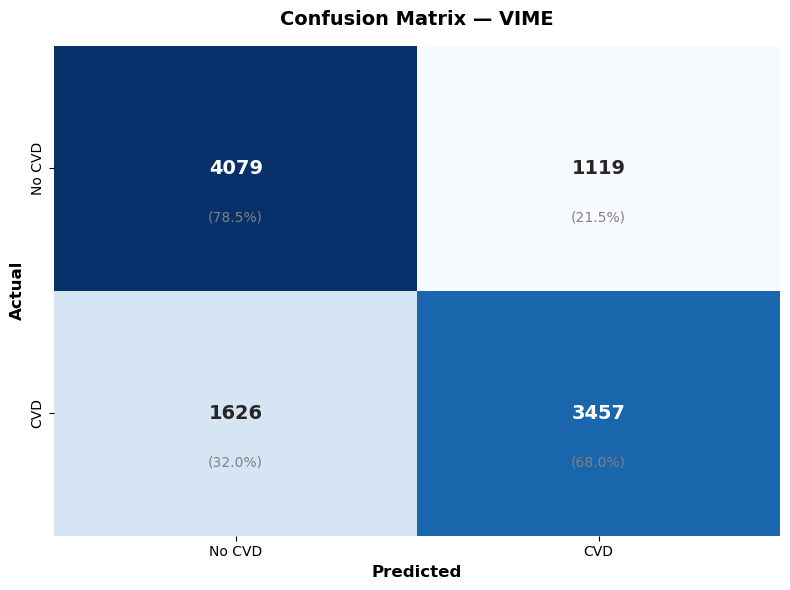

Saved: vime_confusion_matrix.png


In [23]:
cm = confusion_matrix(y_test, test_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No CVD', 'CVD'],
            yticklabels=['No CVD', 'CVD'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.xlabel('Predicted', fontsize=12, fontweight='bold')
plt.ylabel('Actual', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix — VIME', fontsize=14, fontweight='bold', pad=15)

for i in range(2):
    for j in range(2):
        pct = cm[i, j] / cm[i].sum() * 100
        plt.text(j+0.5, i+0.7, f'({pct:.1f}%)', 
                ha='center', va='center', fontsize=10, color='gray')

plt.tight_layout()
plt.savefig('vime_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: vime_confusion_matrix.png')

## 12. ROC & Precision-Recall Curves

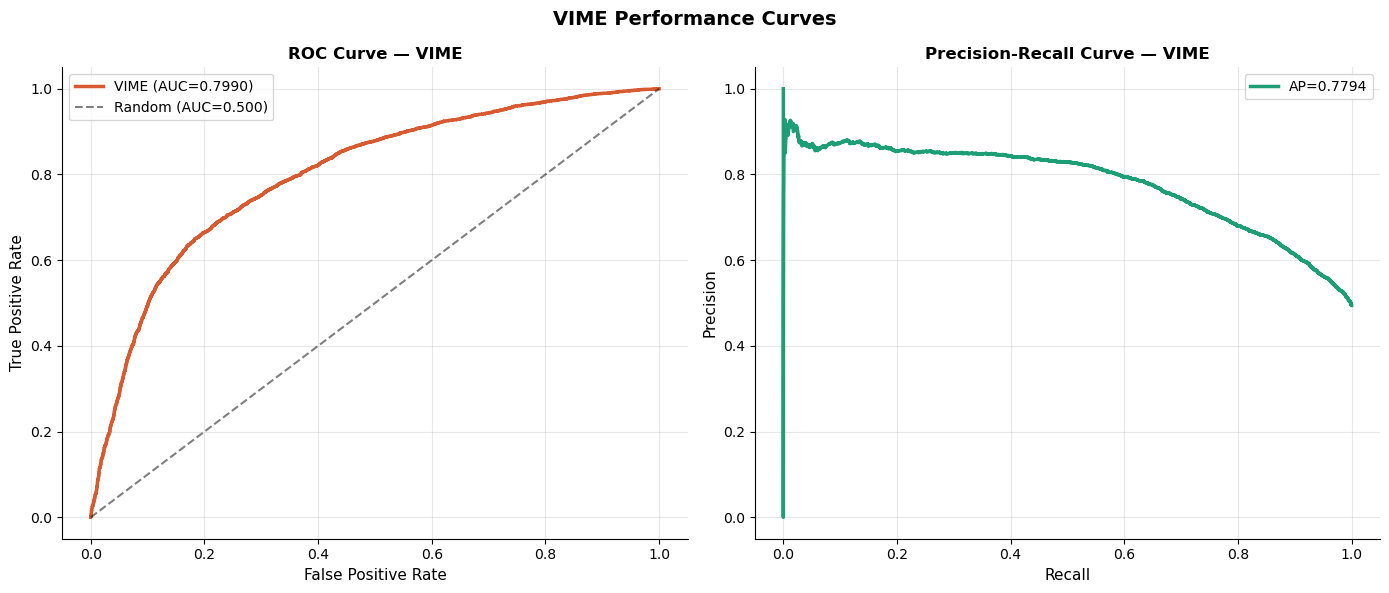

Saved: vime_roc_pr_curves.png


In [24]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
prec, rec, _ = precision_recall_curve(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('VIME Performance Curves', fontsize=14, fontweight='bold')

# ROC
axes[0].plot(fpr, tpr, color='#D85A30', lw=2.5, label=f'VIME (AUC={vime_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random (AUC=0.500)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve — VIME', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)

# PR
axes[1].plot(rec, prec, color='#1D9E75', lw=2.5, label=f'AP={vime_ap:.4f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve — VIME', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('vime_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: vime_roc_pr_curves.png')

## 13. Compare with All Models

In [25]:
all_results = {
    'VIME (Pre-trained)': {'AUC': vime_auc, 'Accuracy': vime_acc, 'F1': vime_f1, 
                           'Precision': vime_prec, 'Recall': vime_rec},
    'Stacking Ensemble': {'AUC': 0.8011, 'Accuracy': 0.7342, 'F1': 0.7189, 
                          'Precision': 0.7532, 'Recall': 0.6876},
    'CatBoost': {'AUC': 0.8008, 'Accuracy': 0.7340, 'F1': 0.7178, 
                 'Precision': 0.7548, 'Recall': 0.6842},
    'XGBoost': {'AUC': 0.8004, 'Accuracy': 0.7328, 'F1': 0.7174, 
                'Precision': 0.7518, 'Recall': 0.6860},
    'FT-Transformer': {'AUC': 0.7998, 'Accuracy': 0.7336, 'F1': 0.7195, 
                       'Precision': 0.7503, 'Recall': 0.6911},
    'Random Forest': {'AUC': 0.7995, 'Accuracy': 0.7322, 'F1': 0.7112, 
                      'Precision': 0.7460, 'Recall': 0.6800},
    'LightGBM': {'AUC': 0.7990, 'Accuracy': 0.7312, 'F1': 0.7149, 
                 'Precision': 0.7515, 'Recall': 0.6817},
    'TabNet': {'AUC': 0.7987, 'Accuracy': 0.7340, 'F1': 0.7155, 
               'Precision': 0.7590, 'Recall': 0.6768},
    'MLP (baseline)': {'AUC': baseline_auc, 'Accuracy': 0.7330, 'F1': 0.7180, 
                       'Precision': 0.7500, 'Recall': 0.6760},
}

results_df = pd.DataFrame(all_results).T.sort_values('AUC', ascending=False)

print('='*75)
print(' COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)')
print('='*75)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-'*75)
for model_name, row in results_df.iterrows():
    marker = ' ← BEST' if model_name == results_df.index[0] else \
             ' ← PRE-TRAINED' if 'VIME' in model_name else ''
    print(f'{model_name:<22} {row["AUC"]:>7.4f} {row["Accuracy"]:>9.4f} '
          f'{row["F1"]:>8.4f} {row["Precision"]:>11.4f} {row["Recall"]:>8.4f}{marker}')
print('='*75)

rank = list(results_df.index).index('VIME (Pre-trained)') + 1
print(f'\nVIME Rank: {rank} out of {len(results_df)}')
print(f'VIME vs Baseline MLP: {vime_auc - baseline_auc:+.4f} AUC')
print(f'VIME vs Best Model:   {vime_auc - results_df["AUC"].iloc[0]:+.4f} AUC')

 COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
---------------------------------------------------------------------------
Stacking Ensemble       0.8011    0.7342   0.7189      0.7532   0.6876 ← BEST
CatBoost                0.8008    0.7340   0.7178      0.7548   0.6842
XGBoost                 0.8004    0.7328   0.7174      0.7518   0.6860
FT-Transformer          0.7998    0.7336   0.7195      0.7503   0.6911
Random Forest           0.7995    0.7322   0.7112      0.7460   0.6800
VIME (Pre-trained)      0.7990    0.7330   0.7158      0.7555   0.6801 ← PRE-TRAINED
LightGBM                0.7990    0.7312   0.7149      0.7515   0.6817
TabNet                  0.7987    0.7340   0.7155      0.7590   0.6768
MLP (baseline)          0.7816    0.7330   0.7180      0.7500   0.6760

VIME Rank: 6 out of 9
VIME vs Baseline MLP: +0.0174 AUC
VIME vs Best Model:   -0.0021 AUC


## 14. Save Models

In [26]:
# Save VIME models
torch.save({
    'pretrain_model_state': pretrain_model.state_dict(),
    'vime_model_state': vime_model.state_dict(),
    'baseline_model_state': baseline.state_dict(),
    'scaler': scaler,
    'feature_names': feature_cols,
    'test_auc': vime_auc,
    'baseline_auc': baseline_auc,
    'improvement': vime_auc - baseline_auc,
}, 'vime_cvd_models.pt')

print('Models saved: vime_cvd_models.pt')

print('\n=== ALL OUTPUT FILES ===')
files = [
    'vime_pretraining_curves.png',
    'vime_vs_baseline.png',
    'vime_confusion_matrix.png',
    'vime_roc_pr_curves.png',
    'vime_cvd_models.pt'
]
for f in files:
    print(f'  {f}')

print(f'\n=== FINAL RESULTS ===')
print(f'VIME AUC:         {vime_auc:.4f}')
print(f'Baseline AUC:     {baseline_auc:.4f}')
print(f'Improvement:      {vime_auc - baseline_auc:+.4f} ({(vime_auc-baseline_auc)/baseline_auc*100:+.2f}%)')
print(f'Best Model AUC:   {results_df["AUC"].iloc[0]:.4f}')
print(f'VIME vs Best:     {vime_auc - results_df["AUC"].iloc[0]:+.4f}')
print('\n🎯 VIME pre-training complete!')

Models saved: vime_cvd_models.pt

=== ALL OUTPUT FILES ===
  vime_pretraining_curves.png
  vime_vs_baseline.png
  vime_confusion_matrix.png
  vime_roc_pr_curves.png
  vime_cvd_models.pt

=== FINAL RESULTS ===
VIME AUC:         0.7990
Baseline AUC:     0.7816
Improvement:      +0.0174 (+2.23%)
Best Model AUC:   0.8011
VIME vs Best:     -0.0021

🎯 VIME pre-training complete!


In [27]:
#Save VIME probability output
np.save('proba_vime.npy', test_probs)
np.save('pred_vime.npy', test_preds)
np.save('y_test.npy', y_test)

In [28]:
# Run this in VIME notebook to check current dataset size
print(f"df shape: {df.shape}")
# Must show (68534, 11) — if it shows (68653, 11) the cleaning cell did not run

df shape: (68534, 16)
